In [2]:
import pandas as pd

data = pd.read_csv('output_site_120V_focus_7_(L)_48.9.csv')

In [ ]:
data['Time'] = pd.to_datetime(data['Time'], format="%Y-%m-%d %H:%M:%S%z")
data['kWh'] = data['Water Heating Electric Power (kW)'] / 60
daily = data.groupby(data['Time'].dt.date).agg({'Water Heating Electric Power (kW)' : 'sum', "Hot Water Delivered (kW)" : "sum", "Draw Data" : "sum", "kWh" : "sum" })
daily['COP'] = daily['Hot Water Delivered (kW)'] / daily['Water Heating Electric Power (kW)']
#Compute cop

#Compare consumption
ground = pd.read_csv('..\\..\\ochre\\defaults\\Input Files\\cleaned_focus_7.csv')
data_kWh = data['Water Heating Electric Power (kW)'].sum()/60
ground_kWh = ground['kW'][:len(data)].sum()/60
ground['kWh'] = ground['kW'] / 60



print(f"Total energy consumption from Slipstream data: {data_kWh} kWh")
print(f"Error: {abs(data_kWh - ground_kWh)/ground_kWh * 100:.2f}%")

AttributeError: Can only use .dt accessor with datetimelike values

In [28]:
ground['datetime'] = pd.to_datetime(ground['datetime'], format="%Y-%m-%d %H:%M:%S%z")
ground_daily = ground.groupby(ground['datetime'].dt.date).agg({'kWh' : 'sum', "gallons" : "sum" })

In [29]:
ground_daily

,kWh,gallons
datetime,,
2023-12-21,0.964877,13.684477
2023-12-22,1.029036,17.706655
2023-12-23,0.827737,11.799396
2023-12-24,1.820503,38.306456
2023-12-25,0.787472,13.724799
...,...,...
2024-09-03,1.338701,33.613918
2024-09-04,0.959368,18.956657
2024-09-05,0.465508,6.023187


In [19]:
ground['kWh'] = ground['kW'] / 60

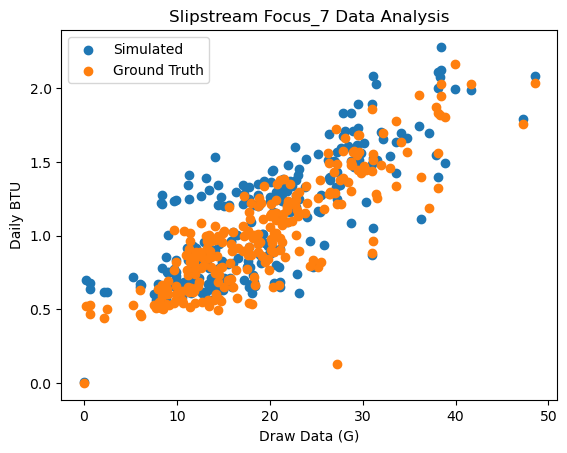

In [32]:
#daily = data
import matplotlib.pyplot as plt
#Daily draw comparison to ground truth
#plt.scatter(daily['gallons']/3.7854, daily['kWh'] * 3412.14) #Convert to kWh/day, then to BTU
plt.scatter(daily['Draw Data']/3.7854, daily['kWh'], label = "Simulated") #Convert to kWh/day, then to BTU
plt.scatter(ground_daily['gallons'], ground_daily['kWh'], label = "Ground Truth") #Convert to kWh/day, then to BTU
plt.xlabel('Draw Data (G)')
plt.ylabel('Daily BTU')
#plt.ylabel('Water Heating Electric Power (BTU))')
plt.title('Slipstream Focus_7 Data Analysis')
#plt.xlim(0, 300)
#plt.ylim(0, 60000)

plt.legend()
plt.show()


In [ ]:
#Ground Truth
daily = ground.groupby(ground['datetime'].dt.date).agg({'kWh' : 'sum', 'gallons' : 'sum' })
import matplotlib.pyplot as plt
plt.scatter(daily['gallons']/3.7854, daily['kWh'] * 3412.14, label = 'Ground Truth') #Convert to kWh/day, then to BTU
#plt.scatter(daily['Draw Data']/3.7854, daily['kWh'] * 3412.14) #Convert to kWh/day, then to BTU
plt.xlabel('Draw Data (G)')
plt.ylabel('Daily BTU')
#plt.ylabel('Water Heating Electric Power (BTU))')
plt.title('Slipstream Focus_7 Data Analysis')
#plt.xlim(0, 300)
#plt.ylim(0, 60000)
plt.xlim(0, 50)
plt.ylim(0, 8000)

plt.grid()
plt.show()

KeyError: "Column(s) ['kWh'] do not exist"

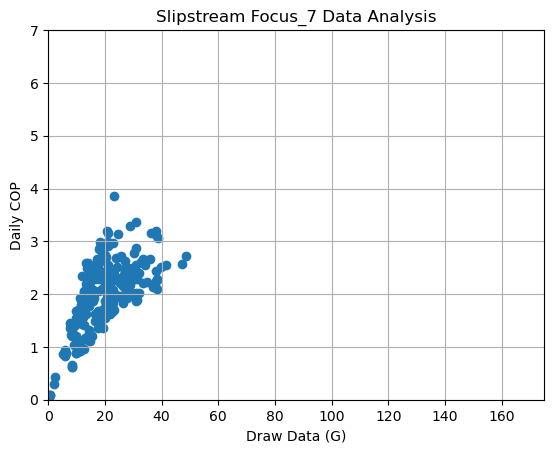

In [22]:
daily
import matplotlib.pyplot as plt

plt.scatter(daily['Draw Data']/3.7854, daily['COP'])#daily['Water Heating Electric Power (kW)'] * 3412.14)
plt.xlabel('Draw Data (G)')
plt.ylabel('Daily COP')
#plt.ylabel('Water Heating Electric Power (BTU))')
plt.title('Slipstream Focus_7 Data Analysis')
plt.xlim(0, 175)
plt.ylim(0, 7)
plt.grid()
plt.show()


In [ ]:
#Time series
import matplotlib.pyplot as plt
day = 5
min_range = day * 1400
max_range = 9000

fig, ax = plt.subplots()

ax.set_title(f'Site: Focus 07')
ax.plot(['rh_air_vol_edge'][min_range:max_range], label='Relative Humidity')
ax.set_xlabel('Time (mins)')
ax.set_ylabel('Relative Humidity (%)')

ax2 = ax.secondary_yaxis('right')
ax2.set_ylabel('Temperature (F)')
ax.plot(site_df['t_inlet_air'][min_range:max_range], label='Inlet Air Temperature')
ax.plot(site_df['t_air_vol'][min_range:max_range], label='Air Volume Temperature')
ax.plot(site_df['t_air_vol_edge'][min_range:max_range], label='Air Volume Edge Temperature')
#ax.plot(site_df['tCWIn'][min_range:max_range], label='Cold Water Inlet Temperature')
#ax.plot(site_df['tHWOut'][min_range:max_range], label='Hot Water Outlet Temperature')
ax.legend()
